# Early Warning of Systemic Banking Crises: 150 Years of Macro-Financial History, Machine Learning and Shapley Values

Banking crises are rare, very expensive and surprisingly alike: most follow years of fast credit growth. Supervisors want to see the next one coming early enough to raise capital buffers in time. This notebook asks whether machine learning can give that warning, using 150 years of history, and how far its signals can be trusted.

**What it does.** It predicts systemic banking crises one to two years ahead in 18 advanced economies from 1870 to 2020, using the Jordà–Schularick–Taylor Macrohistory Database (88 crises).

**Models.** Six model families use the same macro-financial indicators: logistic regression, random forest, extremely randomised trees, LightGBM, an RBF support vector machine and a Keras neural network.

The indicators are credit growth, the yield-curve slope, house and equity prices, the current account, the debt service burden, and their **global** counterparts.

**Validation, two ways:**

- **leave-one-country-out**, so a country's own history never helps predict its own crises;
- a **recursive pseudo-real-time** exercise that, for every year from 1980, trains only on the past.

Shapley values open the black box, in particular the interaction between **credit booms and a flat yield curve**. A policy-loss threshold turns probabilities into warnings with known false-alarm rates.

**Data.** Jordà–Schularick–Taylor Macrohistory Database, release 6 (macrohistory.net).

**Methods.** Early-warning target design (pre-crisis window, removal of post-crisis bias), logistic regression, random forest, extra trees, LightGBM, SVM and an MLP (Keras 3), with bootstrap AUC intervals, SHAP and signal-extraction thresholds (usefulness).

## 1. Early-warning models in macroprudential policy

Banking crises are rare, costly and strikingly similar. They cost on average 5–10% of GDP, and the typical one follows a **credit boom**: credit grows faster than income for several years, often alongside a housing boom, while the yield curve flattens and external imbalances build.

Supervisors use early-warning models to time macroprudential tools, such as the **countercyclical capital buffer**. Its Basel guidance anchors on the credit-to-GDP gap, which has to be announced a year before it bites. Hence the target here: a crisis in **one or two years**.

Two design rules from the literature (Schularick–Taylor 2012; Bluwstein, Buckmann, Joseph, Kapadia and Şimşek 2023) are followed:
- **Pre-crisis window.** The target is 1 if a crisis starts in *t+1* or *t+2*. The crisis year itself and the four years after it are removed: macro data behave differently while a crisis unfolds (*post-crisis bias*).
- **World wars excluded.** 1914–1919 and 1939–1947 are dropped.

With only 88 crises in 150 years, ML methods must be validated very carefully. The question is whether they find stable non-linear patterns or just memorise history.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
os.environ.setdefault("KERAS_BACKEND", "torch")

# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import keras
import lightgbm as lgb
import shap
from keras import layers
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 37
rng = np.random.default_rng(SEED)
keras.utils.set_random_seed(SEED)
JST_PAGE = "https://www.macrohistory.net/database/"
HORIZON = (1, 2)  # warn of a crisis starting one or two years ahead
# years after a crisis start removed from the sample
POST_CRISIS_DROP = 4
WARS = list(range(1914, 1920)) + list(range(1939, 1948))
RECURSIVE_START = 1980  # first year of the pseudo-real-time exercise
THETA = 0.5  # policymaker's relative aversion to missed crises vs false alarms

print(
    f"keras {keras.__version__} ({keras.backend.backend()}) · lightgbm"
    f" {lgb.__version__} · shap {shap.__version__} · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

keras 3.15.1 (torch) · lightgbm 4.7.0 · shap 0.54.1 · run on 2026-10-20


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. The Macrohistory Database

The JST database is the standard source for long-run macro-financial history. It has annual data for 18 advanced economies since 1870, including:
- bank credit to the non-financial private sector;
- house prices, equity returns and interest rates;
- the systemic banking crisis chronology (variable `crisisJST`).

The download link is read from the database page, so the notebook picks up the current file version.

In [3]:
def fetch_jst():
    page = requests.get(JST_PAGE, headers=BROWSER_HEADERS, timeout=60).text
    href = re.search(
        r'href="(/app/download/[^"]+JSTdataset[^"]+\.xlsx[^"]*)"', page
    ).group(1)
    raw = requests.get(
        "https://www.macrohistory.net" + href,
        headers=BROWSER_HEADERS,
        timeout=120,
    ).content
    return pd.read_excel(io.BytesIO(raw))


jst = cached("jst_macrohistory", fetch_jst, max_age_hours=24 * 30)
print(
    f"{len(jst):,} country-years · {jst['country'].nunique()} countries ·"
    f" {jst['year'].min()}–{jst['year'].max()} ·"
    f" {int(jst['crisisJST'].sum())} systemic crises"
)
jst.loc[jst["crisisJST"] == 1].groupby("country")["year"].apply(
    lambda s: ", ".join(map(str, s))
).to_frame("crisis start years")

2,718 country-years · 18 countries · 1870–2020 · 88 systemic crises


,crisis start years
country,
Australia,"1893, 1989"
Belgium,"1870, 1876, 1885, 1925, 1931, 1934, 1939, 2008"
Canada,1907
Denmark,"1877, 1885, 1908, 1921, 1987, 2008"
Finland,"1877, 1900, 1921, 1931, 1991"
France,"1882, 1889, 1930, 2008"
Germany,"1873, 1891, 1901, 1931, 2008"
Ireland,2008
Italy,"1873, 1887, 1893, 1907, 1921, 1930, 1935, 1990..."


## 4. Indicators and the target

All indicators are measured at the end of year *t*.

| indicator | definition |
|---|---|
| credit/GDP change | 2-year change in bank loans to GDP (pp) |
| real credit growth | 2-year log growth of loans deflated by CPI |
| yield-curve slope | long-term rate − short-term rate |
| real house prices | 2-year log change of nominal house prices / CPI |
| real equity prices | 2-year cumulative real capital gain on equities |
| current account | current account / GDP |
| debt service proxy | 2-year change in loans/GDP × long-term rate |
| inflation | CPI inflation |
| real consumption | 2-year growth of real consumption per capita |
| public debt | 2-year change in public debt / GDP |
| **global credit** | cross-country average credit/GDP change, excluding the country itself |
| **global slope** | cross-country average yield-curve slope, excluding the country itself |

Global variables matter because crises cluster: 1890, 1907, 1931 and 2008. Missing values (about 10% of early years) are imputed with the training-set median for the models that need complete data. LightGBM handles them natively.

In [4]:
d = jst.sort_values(["country", "year"]).copy()
d["credit_gdp"] = d["tloans"] / d["gdp"] * 100
d["credit_gdp_chg"] = d["credit_gdp"] - d.groupby("country")[
    "credit_gdp"
].shift(2)
d["real_credit"] = np.log(d["tloans"] / d["cpi"])
d["real_credit_gr"] = (
    d["real_credit"] - d.groupby("country")["real_credit"].shift(2)
) * 100
d["slope"] = d["ltrate"] - d["stir"]
d["real_hp"] = np.log(d["hpnom"] / d["cpi"])
d["real_hp_gr"] = (
    d["real_hp"] - d.groupby("country")["real_hp"].shift(2)
) * 100
d["infl"] = (d["cpi"] / d.groupby("country")["cpi"].shift(1) - 1) * 100
real_eq = np.log1p(d["eq_capgain"]) - np.log1p(d["infl"] / 100)
d["real_eq_gr"] = (real_eq + real_eq.groupby(d["country"]).shift(1)) * 100
d["ca_gdp"] = d["ca"] / d["gdp"] * 100
d["dsr_proxy"] = d["credit_gdp"] * d["ltrate"] / 100
d["dsr_chg"] = d["dsr_proxy"] - d.groupby("country")["dsr_proxy"].shift(2)
d["cons_gr"] = (
    np.log(d["rconsbarro"])
    - np.log(d.groupby("country")["rconsbarro"].shift(2))
) * 100
d["pubdebt_chg"] = (
    d["debtgdp"] - d.groupby("country")["debtgdp"].shift(2)
) * 100
for c_, name in [
    ("credit_gdp_chg", "global_credit"),
    ("slope", "global_slope"),
]:
    tot, cnt = d.groupby("year")[c_].transform("sum"), d.groupby("year")[
        c_
    ].transform("count")
    d[name] = (tot - d[c_].fillna(0)) / (cnt - d[c_].notna())
FEATS = [
    "credit_gdp_chg",
    "real_credit_gr",
    "slope",
    "real_hp_gr",
    "real_eq_gr",
    "ca_gdp",
    "dsr_chg",
    "infl",
    "cons_gr",
    "pubdebt_chg",
    "global_credit",
    "global_slope",
]
# winsorise hyperinflation and war outliers
for c_ in FEATS:
    lo, hi = d[c_].quantile([0.01, 0.99])
    d[c_] = d[c_].clip(lo, hi)

cr = d.pivot(index="year", columns="country", values="crisisJST").fillna(0)
ahead = sum(cr.shift(-h) for h in HORIZON).clip(upper=1)
recent = sum(cr.shift(k) for k in range(0, POST_CRISIS_DROP + 1)).clip(upper=1)
d["y"] = (
    d.set_index(["year", "country"])
    .index.map(ahead.stack().to_dict())
    .fillna(0)
    .astype(int)
)
d["in_crisis"] = (
    d.set_index(["year", "country"])
    .index.map(recent.stack().to_dict())
    .fillna(0)
    .astype(int)
)
S = d[
    (d["in_crisis"] == 0)
    & ~d["year"].isin(WARS)
    & (d["year"] <= d["year"].max() - max(HORIZON))
    & d[["credit_gdp_chg", "slope"]].notna().all(axis=1)
].reset_index(drop=True)
X, y, grp, yr = (
    S[FEATS],
    S["y"].to_numpy(),
    S["country"].to_numpy(),
    S["year"].to_numpy(),
)
print(
    f"Sample: {len(S):,} country-years · {y.sum()} pre-crisis observations"
    f" ({y.mean():.1%}) covering "
    f"{S.loc[S['y'] == 1].groupby('country')['year'].apply(lambda s: (s.diff() != 1).sum()).sum()} crises"
)
S.groupby("y")[FEATS].median().T.round(2).rename(
    columns={0: "tranquil (median)", 1: "pre-crisis (median)"}
)

Sample: 1,689 country-years · 126 pre-crisis observations (7.5%) covering 66 crises


y,tranquil (median),pre-crisis (median)
credit_gdp_chg,1.47,4.59
real_credit_gr,10.10,16.07
slope,0.86,-0.05
real_hp_gr,4.30,7.53
real_eq_gr,5.53,8.14
ca_gdp,-0.09,-1.40
dsr_chg,0.06,0.25
infl,2.36,1.88
cons_gr,4.21,3.51
pubdebt_chg,-0.78,-1.00


## 5. Six models, validated leave-one-country-out

Each country is held out in turn. The models are fitted on the other 17 countries' history and predict every year of the held-out country.

| model | settings |
|---|---|
| logistic regression | standardised features, L2 penalty |
| random forest | 500 trees, min leaf 5, balanced classes |
| extra trees | 500 trees, min leaf 5, balanced classes |
| LightGBM | 300 shallow trees, positive class up-weighted |
| SVM | RBF kernel, balanced classes (decision function as score) |
| neural network | Keras MLP 32-16, dropout, class weights, 100 epochs |

The ensemble averages the six models' percentile ranks. **AUC** is the standard early-warning metric, because it does not depend on a threshold. A cross-country block bootstrap gives the 90% interval.

In [5]:
def make_models():
    pos_w = (1 - y.mean()) / y.mean()
    return {
        "logit": make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            LogisticRegression(C=0.5, max_iter=2000),
        ),
        "random forest": make_pipeline(
            SimpleImputer(strategy="median"),
            RandomForestClassifier(
                500,
                min_samples_leaf=5,
                class_weight="balanced_subsample",
                n_jobs=-1,
                random_state=SEED,
            ),
        ),
        "extra trees": make_pipeline(
            SimpleImputer(strategy="median"),
            ExtraTreesClassifier(
                500,
                min_samples_leaf=5,
                class_weight="balanced",
                n_jobs=-1,
                random_state=SEED,
            ),
        ),
        "LightGBM": lgb.LGBMClassifier(
            n_estimators=300,
            learning_rate=0.03,
            num_leaves=7,
            min_child_samples=20,
            subsample=0.8,
            subsample_freq=1,
            colsample_bytree=0.8,
            scale_pos_weight=pos_w,
            verbose=-1,
            random_state=SEED,
        ),
        "SVM": make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            SVC(C=1.0, gamma="scale", class_weight="balanced"),
        ),
    }


def mlp_fit_predict(Xa, ya, Xb):
    imp, sc = SimpleImputer(strategy="median").fit(Xa), StandardScaler()
    A = sc.fit_transform(imp.transform(Xa)).astype("float32")
    B = sc.transform(imp.transform(Xb)).astype("float32")
    m = keras.Sequential([
        keras.Input((A.shape[1],)),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(16, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid"),
    ])
    m.compile(
        optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy"
    )
    w = {0: 1.0, 1: float((1 - ya.mean()) / ya.mean())}
    m.fit(
        A,
        ya.astype("float32"),
        epochs=100,
        batch_size=128,
        class_weight=w,
        verbose=0,
    )
    return m.predict(B, verbose=0).ravel()


def fit_predict_all(Xa, ya, Xb):
    out = {}
    for k, m in make_models().items():
        m.fit(Xa, ya)
        out[k] = (
            m.decision_function(Xb)
            if k == "SVM"
            else m.predict_proba(Xb)[:, 1]
        )
    out["neural network"] = mlp_fit_predict(Xa, ya, Xb)
    return out


MODELS = [
    "logit",
    "random forest",
    "extra trees",
    "LightGBM",
    "SVM",
    "neural network",
]
loco = {k: np.full(len(S), np.nan) for k in MODELS}
for c_ in np.unique(grp):
    te = grp == c_
    p_ = fit_predict_all(X[~te], y[~te], X[te])
    for k in MODELS:
        loco[k][te] = p_[k]
loco["ensemble"] = np.mean(
    [pd.Series(loco[k]).rank(pct=True) for k in MODELS], axis=0
)


def boot_auc(score_, B=500):
    cs = np.unique(grp)
    idx = {c_: np.where(grp == c_)[0] for c_ in cs}
    aucs = []
    for _ in range(B):
        ii = np.concatenate([idx[c_] for c_ in rng.choice(cs, len(cs))])
        if y[ii].min() != y[ii].max():
            aucs.append(roc_auc_score(y[ii], score_[ii]))
    return np.quantile(aucs, [0.05, 0.95])


loco_tab = pd.DataFrame({
    k: {
        "AUC": roc_auc_score(y, v),
        "AUC 5%": boot_auc(v)[0],
        "AUC 95%": boot_auc(v)[1],
        "PR-AUC": average_precision_score(y, v),
    }
    for k, v in loco.items()
}).T
loco_tab.loc["credit/GDP change alone"] = [
    roc_auc_score(y, X["credit_gdp_chg"].fillna(0)),
    *boot_auc(X["credit_gdp_chg"].fillna(0).to_numpy()),
    average_precision_score(y, X["credit_gdp_chg"].fillna(0)),
]
loco_tab.loc["base rate"] = [0.5, 0.5, 0.5, y.mean()]
loco_tab.round(3)

,AUC,AUC 5%,AUC 95%,PR-AUC
logit,0.80,0.77,0.83,0.33
random forest,0.84,0.80,0.88,0.37
extra trees,0.84,0.81,0.88,0.40
LightGBM,0.82,0.79,0.85,0.38
SVM,0.78,0.76,0.80,0.23
neural network,0.81,0.77,0.85,0.37
ensemble,0.83,0.80,0.87,0.36
credit/GDP change alone,0.68,0.63,0.72,0.18
base rate,0.50,0.50,0.50,0.07


## 6. Pseudo-real time: training only on the past

Leave-one-country-out still lets a model learn the 2008 crisis in other countries while predicting 2008 for the held-out one. Crises cluster, so that overstates real-world skill.

**The recursive exercise.** For every year *T* from 1980 to 2018, the models are trained on all country-years with *t + 2 < T*, so the outcomes are known by then. They then predict year *T* for all 18 countries. The out-of-sample period contains the Nordic crises of the early 1990s, Japan 1997 and the global financial crisis.

In [6]:
rec = {k: np.full(len(S), np.nan) for k in MODELS}
for T in range(RECURSIVE_START, int(yr.max()) + 1):
    tr_, te_ = yr + max(HORIZON) < T, yr == T
    if te_.sum() == 0 or y[tr_].sum() < 10:
        continue
    p_ = fit_predict_all(X[tr_], y[tr_], X[te_])
    for k in MODELS:
        rec[k][te_] = p_[k]
mask = yr >= RECURSIVE_START
rec["ensemble"] = np.full(len(S), np.nan)
rec["ensemble"][mask] = np.mean(
    [pd.Series(rec[k][mask]).rank(pct=True) for k in MODELS], axis=0
)
rec_tab = pd.DataFrame({
    k: {
        "AUC": roc_auc_score(y[mask], v[mask]),
        "PR-AUC": average_precision_score(y[mask], v[mask]),
    }
    for k, v in rec.items()
}).T
rec_tab.loc["credit/GDP change alone"] = [
    roc_auc_score(y[mask], X.loc[mask, "credit_gdp_chg"].fillna(0)),
    average_precision_score(y[mask], X.loc[mask, "credit_gdp_chg"].fillna(0)),
]
print(
    f"Recursive out-of-sample {RECURSIVE_START}–{int(yr.max())}:"
    f" {mask.sum()} country-years, {y[mask].sum()} pre-crisis observations"
)
rec_tab.round(3)

Recursive out-of-sample 1980–2018: 584 country-years, 46 pre-crisis observations


,AUC,PR-AUC
logit,0.74,0.25
random forest,0.75,0.27
extra trees,0.75,0.28
LightGBM,0.70,0.17
SVM,0.62,0.12
neural network,0.67,0.24
ensemble,0.73,0.24
credit/GDP change alone,0.72,0.26


## 7. Opening the black box: Shapley values

SHAP values of a random forest fitted on the full sample show:
- which indicators drive the predicted crisis probability;
- **how**: the shape of each effect and the interactions.

The literature's headline finding is that a credit boom is far more dangerous when the yield curve is flat or inverted. A flat curve squeezes bank margins and signals tight money. The SHAP interaction chart tests that directly.

In [7]:
rf_full = make_models()["random forest"].fit(X, y)
Xi = pd.DataFrame(rf_full[0].transform(X), columns=FEATS)
expl = shap.TreeExplainer(rf_full[-1])
sv = expl.shap_values(Xi.iloc[::2])
sv = (
    sv[..., 1] if np.ndim(sv) == 3 else (sv[1] if isinstance(sv, list) else sv)
)
Xs_ = Xi.iloc[::2]
shap_imp = pd.Series(np.abs(sv).mean(0), index=FEATS).sort_values(
    ascending=False
)
hi_c = Xs_["credit_gdp_chg"] > Xs_["credit_gdp_chg"].quantile(0.8)
flat = Xs_["slope"] < Xs_["slope"].quantile(0.25)
inter = pd.DataFrame(
    {
        "credit boom (top quintile)": [
            sv[hi_c & ~flat, FEATS.index("credit_gdp_chg")].mean(),
            sv[hi_c & flat, FEATS.index("credit_gdp_chg")].mean(),
        ]
    },
    index=["normal/steep curve", "flat curve (bottom quartile)"],
)
display(shap_imp.round(4).to_frame("mean |SHAP| (probability)"))
inter.round(4).rename_axis("SHAP of credit/GDP change")

,mean |SHAP| (probability)
global_slope,0.10
slope,0.06
credit_gdp_chg,0.05
global_credit,0.05
real_credit_gr,0.04
dsr_chg,0.03
infl,0.03
ca_gdp,0.03
pubdebt_chg,0.02
cons_gr,0.02


,credit boom (top quintile)
SHAP of credit/GDP change,
normal/steep curve,0.04
flat curve (bottom quartile),0.05


## 8. From probabilities to warnings

A supervisor needs a yes/no signal. Following Alessi and Detken (2011), the threshold minimises a policy loss:

L(τ) = θ · (missed-crisis rate) + (1 − θ) · (false-alarm rate),

with θ = 0.5 (equal aversion). **Relative usefulness** is the share of the loss of a no-model benchmark that the model removes:
- 0 means no better than ignoring the model;
- 1 means perfect.

The threshold is chosen on the leave-one-country-out scores and then applied to the pseudo-real-time scores.

In [8]:
def usefulness(score_, yy, thr):
    s_ = score_ >= thr
    miss = 1 - s_[yy == 1].mean()
    fa = s_[yy == 0].mean()
    loss = THETA * miss + (1 - THETA) * fa
    return loss, miss, fa, 1 - loss / min(THETA, 1 - THETA)


warn = {}
for k in ["logit", "random forest", "LightGBM", "ensemble"]:
    v = loco[k]
    grid = np.quantile(v, np.linspace(0.5, 0.97, 60))
    best = min(grid, key=lambda t: usefulness(v, y, t)[0])
    # threshold as a percentile, transferable to the recursive scores
    q_best = (v < best).mean()
    l1, m1, f1, u1 = usefulness(v, y, best)
    vr = rec[k][mask]
    l2, m2, f2, u2 = usefulness(vr, y[mask], np.quantile(vr, q_best))
    warn[k] = {
        "threshold percentile": q_best,
        "LOCO: missed %": m1 * 100,
        "LOCO: false alarms %": f1 * 100,
        "LOCO: usefulness": u1,
        "recursive: missed %": m2 * 100,
        "recursive: false alarms %": f2 * 100,
        "recursive: usefulness": u2,
    }
warn = pd.DataFrame(warn).T
warn.round(2)

,threshold percentile,LOCO: missed %,LOCO: false alarms %,LOCO: usefulness,recursive: missed %,recursive: false alarms %,recursive: usefulness
logit,0.79,30.95,17.47,0.52,50.00,18.96,0.31
random forest,0.70,19.84,26.04,0.54,34.78,27.14,0.38
LightGBM,0.79,31.75,17.53,0.51,47.83,18.77,0.33
ensemble,0.75,27.78,20.67,0.52,41.30,21.56,0.37


## 9. The 2000s through the models' eyes

Below are the pseudo-real-time ensemble scores for the countries hit in 2007–2008, against those that were not. Every score comes from a model trained only on data available at the time.

In [9]:
S["rec_ens"] = rec["ensemble"]
S["loco_ens"] = loco["ensemble"]
gfc = S[S["year"].between(2000, 2007)].pivot(
    index="country", columns="year", values="rec_ens"
)
hit = S.loc[
    (S["year"].between(2005, 2007)) & (S["y"] == 1), "country"
].unique()
gfc.insert(0, "crisis 2007–08", gfc.index.isin(hit))
latest = (
    S[S["year"] == S["year"].max()]
    .set_index("country")[["rec_ens", "credit_gdp_chg", "real_hp_gr", "slope"]]
    .sort_values("rec_ens", ascending=False)
)
display(gfc.sort_values(2006, ascending=False).round(2))
print(
    f"Latest scored year in the data: {int(S['year'].max())} (the JST release"
    f" ends in {int(jst['year'].max())}; the target needs two years ahead)"
)
latest.round(2)

year,crisis 2007–08,2000,2001,2002,2003,2004,2005,2006,2007
country,,,,,,,,,
Australia,False,0.90,0.71,0.71,0.87,0.74,0.72,0.90,0.97
Spain,True,0.91,0.94,0.72,0.69,0.72,0.80,0.89,0.97
Ireland,True,0.88,0.55,0.22,0.17,0.51,0.71,0.88,0.95
USA,True,0.79,0.76,0.55,0.46,0.37,0.72,0.83,NaN
Portugal,True,0.97,0.91,0.65,0.52,0.49,0.57,0.83,0.92
UK,True,0.87,0.90,0.81,0.73,0.61,0.54,0.82,NaN
Italy,True,0.77,0.82,0.52,0.29,0.16,0.31,0.79,0.91
Denmark,True,0.80,0.87,0.58,0.31,0.19,0.39,0.74,0.90
France,True,0.40,0.72,0.58,0.40,0.18,0.26,0.58,0.90


Latest scored year in the data: 2018 (the JST release ends in 2020; the target needs two years ahead)


,rec_ens,credit_gdp_chg,real_hp_gr,slope
country,,,,
Netherlands,0.36,-8.65,13.43,0.90
Australia,0.32,-4.49,2.67,1.18
Germany,0.29,0.84,8.75,0.76
Spain,0.28,-14.15,8.92,1.70
Denmark,0.26,-5.52,7.19,0.95
France,0.25,5.32,3.17,1.40
Ireland,0.24,-7.75,16.74,1.27
Italy,0.24,-7.64,-4.21,2.49
UK,0.24,-0.60,2.48,1.24


## 10. Charts and dashboard

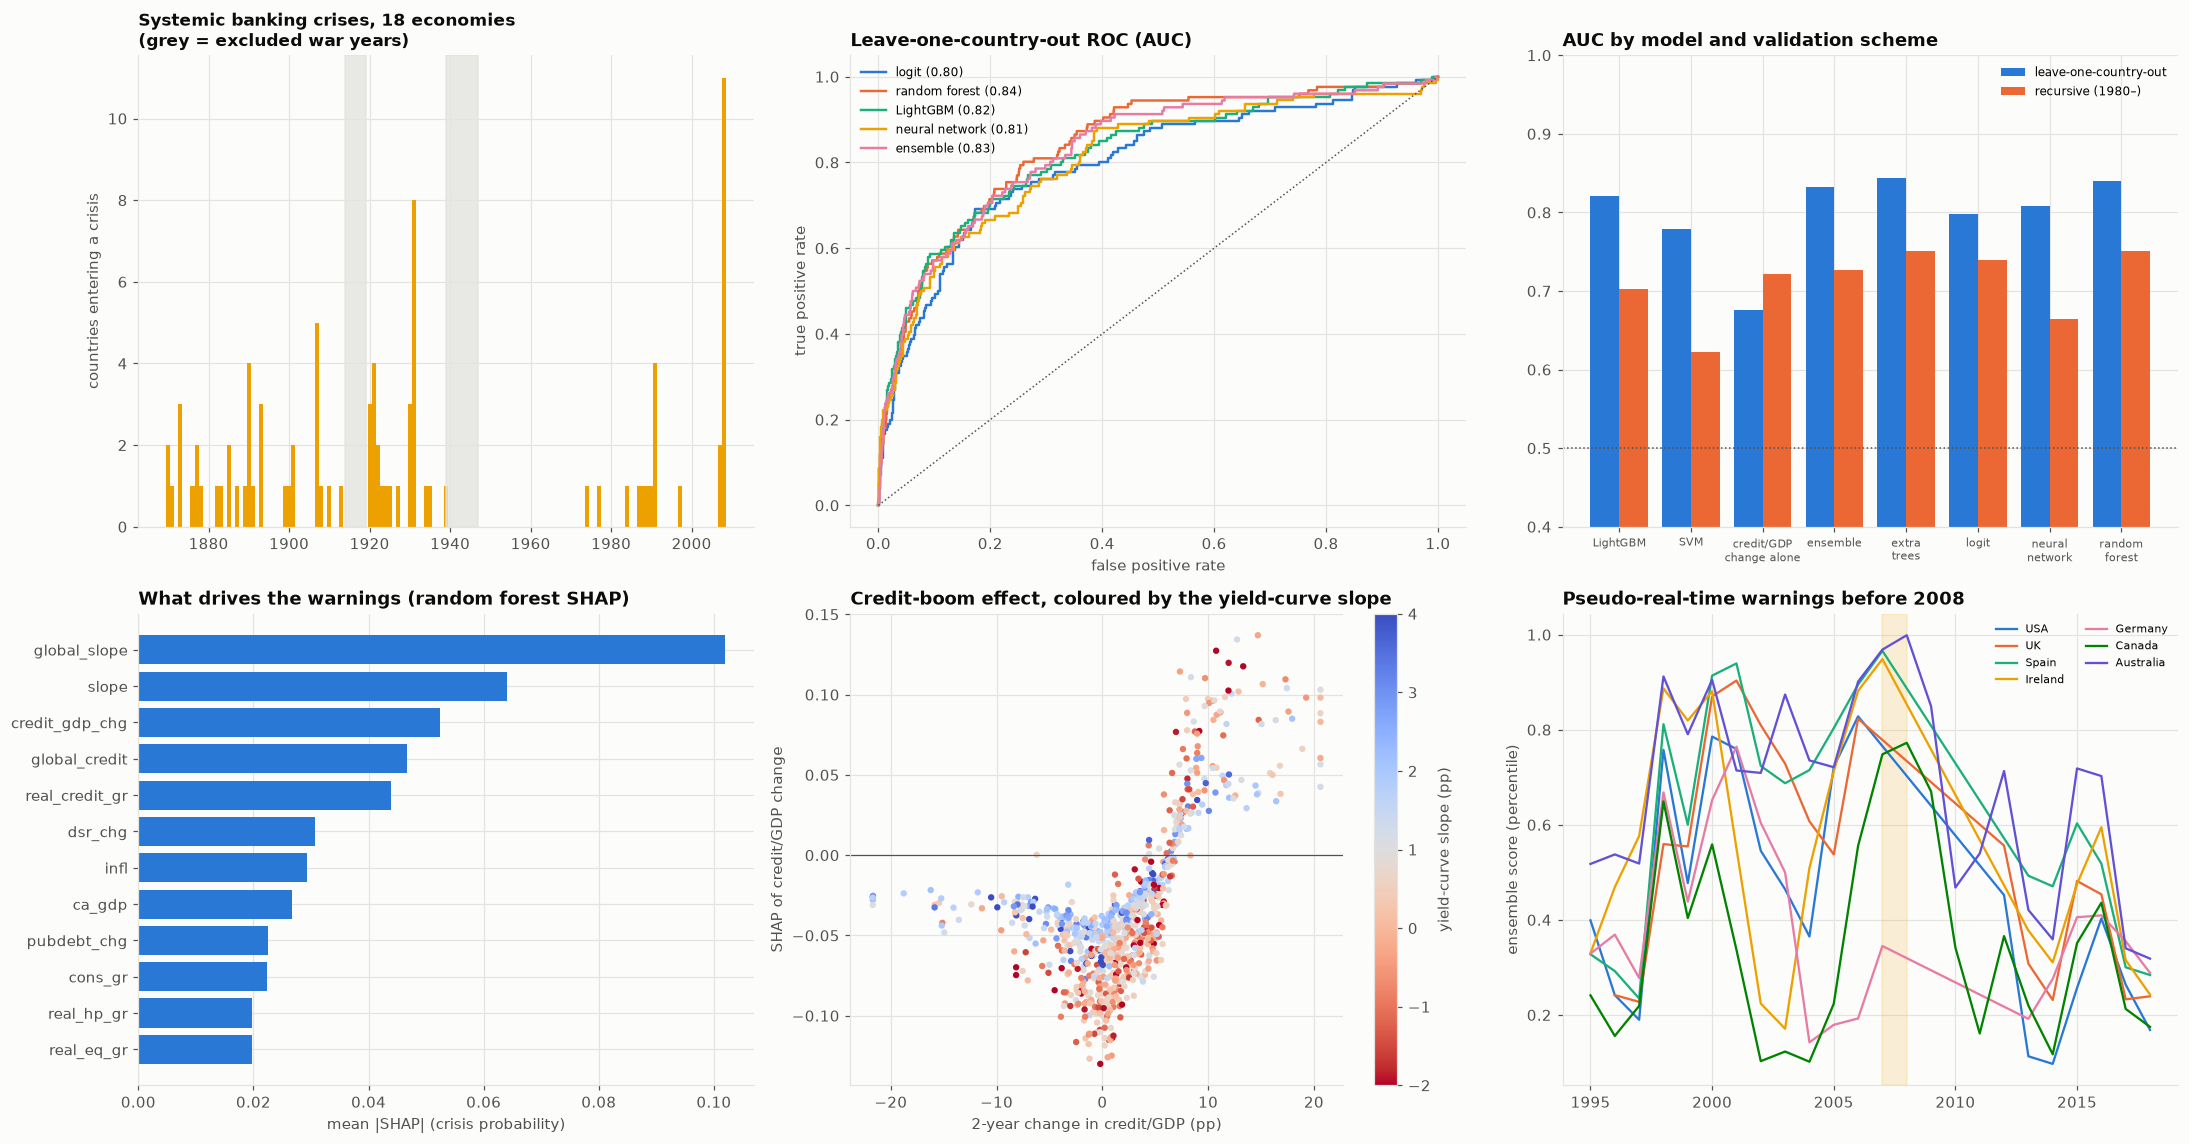

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10.5))
ax = axes[0, 0]
cy = jst[jst["crisisJST"] == 1].groupby("year").size()
ax.bar(cy.index, cy.values, color=PALETTE[3], width=1.0)
for a_, b_ in [(1914, 1919), (1939, 1947)]:
    ax.axvspan(a_, b_, color=GRID, alpha=0.8)
ax.set_ylabel("countries entering a crisis")
ax.set_title(
    "Systemic banking crises, 18 economies\n(grey = excluded war years)",
    fontsize=11,
)
ax = axes[0, 1]
for k, c in zip(
    ["logit", "random forest", "LightGBM", "neural network", "ensemble"],
    PALETTE,
):
    fpr, tpr, _ = roc_curve(y, loco[k])
    ax.plot(
        fpr, tpr, color=c, lw=1.6, label=f"{k} ({loco_tab.loc[k, 'AUC']:.2f})"
    )
ax.plot([0, 1], [0, 1], color=INK_2, ls=":", lw=1)
ax.legend(fontsize=8)
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate")
ax.set_title("Leave-one-country-out ROC (AUC)")
ax = axes[0, 2]
comp_ = (
    pd.DataFrame({
        "leave-one-country-out": loco_tab["AUC"],
        "recursive (1980–)": rec_tab["AUC"],
    })
    .drop(index="base rate", errors="ignore")
    .dropna()
)
xx = np.arange(len(comp_))
ax.bar(
    xx - 0.2, comp_.iloc[:, 0], 0.4, color=PALETTE[0], label=comp_.columns[0]
)
ax.bar(
    xx + 0.2, comp_.iloc[:, 1], 0.4, color=PALETTE[1], label=comp_.columns[1]
)
ax.axhline(0.5, color=INK_2, ls=":", lw=1)
ax.set_ylim(0.4, 1.0)
ax.set_xticks(xx)
ax.set_xticklabels([s.replace(" ", "\n", 1) for s in comp_.index], fontsize=7)
ax.legend(fontsize=8)
ax.set_title("AUC by model and validation scheme")
ax = axes[1, 0]
ax.barh(shap_imp.index[::-1], shap_imp.values[::-1], color=PALETTE[0])
ax.set_xlabel("mean |SHAP| (crisis probability)")
ax.set_title("What drives the warnings (random forest SHAP)")
ax = axes[1, 1]
scat = ax.scatter(
    Xs_["credit_gdp_chg"],
    sv[:, FEATS.index("credit_gdp_chg")],
    c=Xs_["slope"],
    cmap="coolwarm_r",
    s=10,
    vmin=-2,
    vmax=4,
)
plt.colorbar(scat, ax=ax, label="yield-curve slope (pp)")
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_xlabel("2-year change in credit/GDP (pp)")
ax.set_ylabel("SHAP of credit/GDP change")
ax.set_title("Credit-boom effect, coloured by the yield-curve slope")
ax = axes[1, 2]
for c_, col in zip(
    ["USA", "UK", "Spain", "Ireland", "Germany", "Canada", "Australia"],
    PALETTE,
):
    s_ = S[(S["country"] == c_) & (S["year"] >= 1995)]
    ax.plot(s_["year"], s_["rec_ens"], color=col, lw=1.5, label=c_)
ax.axvspan(2007, 2008, color=PALETTE[3], alpha=0.15)
ax.set_ylabel("ensemble score (percentile)")
ax.legend(fontsize=7, ncol=2)
ax.set_title("Pseudo-real-time warnings before 2008")
plt.tight_layout()
save_fig(fig, "01_crisis_early_warning")
plt.show()

In [11]:
hm = S[S["year"] >= RECURSIVE_START].pivot(
    index="country", columns="year", values="rec_ens"
)
starts = jst[(jst["crisisJST"] == 1) & (jst["year"] >= RECURSIVE_START)]
dash = make_subplots(rows=1, cols=1)
dash.add_trace(
    go.Heatmap(
        z=hm.values,
        x=hm.columns,
        y=hm.index,
        colorscale="Reds",
        zmin=0,
        zmax=1,
        colorbar=dict(title="score"),
    )
)
dash.add_trace(
    go.Scatter(
        x=starts["year"],
        y=starts["country"],
        mode="markers",
        marker=dict(symbol="x", size=11, color="black"),
        name="crisis start",
    )
)
dash.update_layout(
    height=650,
    width=1250,
    template="simple_white",
    title=(
        "Pseudo-real-time crisis warnings (ensemble percentile; x = crisis"
        " start; blank = crisis or post-crisis years)"
    ),
)
save_dashboard(dash, "dashboard")
dash.show()

Dashboard saved: outputs/dashboard.html and .png


## 11. Reading the results and limitations

**What precedes a crisis.**
- In the two years before a crisis, the median country shows:
  - credit/GDP up 4.6 pp (1.5 pp in tranquil times), real credit growth of 16% over two years, faster house-price and equity growth;
  - a current-account deficit;
  - a **flat yield curve**: median slope −0.05 pp against +0.86 pp.
- Global conditions move the same way: global credit growth is higher, and the global slope is 0.2 pp against 1.0 pp.

**Predictive power, honestly measured.**
- **Leave one country out**, every model beats the credit-to-GDP change alone (AUC 0.68):
  - random forest and extra trees reach AUC 0.84 (90% interval about 0.80–0.88);
  - the ensemble 0.83, LightGBM 0.82, the neural network 0.81, the logit 0.80 and the SVM 0.78.
  - This reproduces the literature's finding that tree ensembles beat the logit.
- **In pseudo real time** (1980–2018, training only on the past) skill drops and the ranking changes:
  - random forest and extra trees 0.75, logit 0.74, ensemble 0.73;
  - credit/GDP change alone 0.72, LightGBM 0.70, neural network 0.66, SVM 0.62.
  - With only 46 pre-crisis observations, mostly the 2007–08 cluster, the flexible models barely beat a single well-chosen indicator out of sample. The SVM and the network overfit the pre-1980 history.
- The practical lesson: random forests are the most robust ML choice. A transparent logit loses little, and both should be judged on pseudo-real-time tests, not cross-validation.

**What drives the warnings.**
- SHAP ranks the **global yield-curve slope** first, then the domestic slope, credit/GDP change, global credit and real credit growth. Asset prices come last.
- Crises are a global-cycle phenomenon: flat curves and credit booms everywhere at once (1890, 1907, 1929, 2006–07).
- The credit effect is strongly non-linear: almost nothing below a 5 pp two-year rise, then rising steeply.
- The SHAP of a credit boom is slightly larger with a flat curve (0.05 vs 0.04 of probability). The interaction is present but weaker than the slope's own effect.

**Warnings a supervisor could use.**
- With equal aversion to missed crises and false alarms, the leave-one-country-out threshold catches about 68–80% of pre-crisis years at a 17–26% false-alarm rate. Usefulness is around 0.5.
- In pseudo real time, usefulness falls to 0.31–0.38: about 50–65% of pre-crisis years caught, at a 19–27% false-alarm rate. That is valuable, not decisive.
- Before 2008 the pseudo-real-time ensemble put Spain, Ireland, Portugal, the UK and the US in the top fifth of scores by 2006–07 (percentiles 0.82–0.97). Those scores came from models trained only on data up to 2004–05.
- Clear misses: **Germany and Switzerland**, whose crises came through foreign exposures rather than a domestic boom. Clear false alarms: **Australia and Canada**, which had booms but no crisis.
- At the end of the sample (2018), no country scores in the warning zone. Credit/GDP was falling almost everywhere after the post-2008 deleveraging.

**Limitations.**
- 88 crises in 150 years, and the recursive test leans on one global event. All AUCs carry wide uncertainty.
- The crisis chronology is a judgement-based classification, and the JST release ends in 2020, so current conditions cannot be scored here.
- Annual data and a two-year window give only coarse timing.
- Advanced economies only. Emerging-market crises (currency and sovereign twin crises) follow different patterns.

In [12]:
loco_tab.to_csv(OUT_DIR / "auc_leave_one_country_out.csv")
rec_tab.to_csv(OUT_DIR / "auc_recursive_out_of_sample.csv")
shap_imp.to_csv(OUT_DIR / "shap_importance.csv", header=["mean_abs_shap"])
warn.to_csv(OUT_DIR / "warning_thresholds_usefulness.csv")
S[["country", "year", "y"] + FEATS + ["loco_ens", "rec_ens"]].to_csv(
    OUT_DIR / "country_year_scores.csv", index=False
)
print(
    "Outputs written:", ", ".join(sorted(p_.name for p_ in OUT_DIR.iterdir()))
)

Outputs written: 01_crisis_early_warning.png, auc_leave_one_country_out.csv, auc_recursive_out_of_sample.csv, country_year_scores.csv, dashboard.html, dashboard.png, shap_importance.csv, warning_thresholds_usefulness.csv


## References

### Finance and regulation

- Schularick, M., & Taylor, A. M. (2012). Credit booms gone bust: Monetary policy, leverage cycles, and financial crises, 1870–2008. *American Economic Review, 102*(2), 1029–1061. https://doi.org/10.1257/aer.102.2.1029
- Jordà, Ò., Schularick, M., & Taylor, A. M. (2017). Macrofinancial history and the new business cycle facts. *NBER Macroeconomics Annual, 31*, 213–263. https://doi.org/10.1086/690241
- Bluwstein, K., Buckmann, M., Joseph, A., Kapadia, S., & Şimşek, Ö. (2023). Credit growth, the yield curve and financial crisis prediction: Evidence from a machine learning approach. *Journal of International Economics, 145*, 103773. https://doi.org/10.1016/j.jinteco.2023.103773
- Alessi, L., & Detken, C. (2011). Quasi real time early warning indicators for costly asset price boom/bust cycles: A role for global liquidity. *European Journal of Political Economy, 27*(3), 520–533. https://doi.org/10.1016/j.ejpoleco.2011.01.003
- Laeven, L., & Valencia, F. (2018). *Systemic banking crises revisited* (IMF Working Paper No. 18/206). International Monetary Fund. https://doi.org/10.5089/9781484376379.001
- Basel Committee on Banking Supervision. (2010). *Guidance for national authorities operating the countercyclical capital buffer*. Bank for International Settlements. https://www.bis.org/publ/bcbs187.htm

### Machine learning and deep learning

- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems, 30*. https://arxiv.org/abs/1705.07874
- Geurts, P., Ernst, D., & Wehenkel, L. (2006). Extremely randomized trees. *Machine Learning, 63*(1), 3–42. https://doi.org/10.1007/s10994-006-6226-1
- Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324
- Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems, 30*. https://proceedings.neurips.cc/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html